# CIFAR-10 DCGAN (AI-Generated, Modern Best Practices)
**CSYE 7380 — Applied Generative AI**

This notebook solves the **same task** as the manual baseline (`../manual/dcgan_manual.ipynb`) —
generate images of a single CIFAR-10 class (`automobile`, 32×32×3) with a DCGAN — but it is rewritten
with **modern, efficient training practices** so the two can be compared head-to-head.

| | Manual baseline | **This notebook (AI)** |
|---|---|---|
| Data feed | `np.random.randint` index sampling | **`tf.data` pipeline** (shuffle / batch / prefetch / cache) |
| Training step | `generator.predict` + 3× `train_on_batch` | **one `@tf.function` `GradientTape` step** (compiled graph, no retrace) |
| Loss | `sigmoid` output + BCE on probabilities | **`from_logits=True`** + **one-sided label smoothing** |
| Generator out | `tanh`, Conv2DTranspose | same (DCGAN convention) |
| Init / norm | default | **`RandomNormal(0, 0.02)`**, `BatchNormalization`, `LeakyReLU`, `Dropout` (D) |
| Metrics | loss curves | loss curves **+ wall-clock ms/step** + sample grids saved to disk |

Everything runs on **Google Colab (GPU)** out of the box (`keras.datasets.cifar10.load_data()` +
`os.makedirs(..., exist_ok=True)`), and also runs locally. Framework: **TensorFlow / Keras**.

> Tip (Colab): *Runtime → Change runtime type → GPU* before running.


## 0. Setup & imports

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from keras import layers
from keras.initializers import RandomNormal

# Reproducibility (best-effort; GPU kernels are not fully deterministic).
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)

print("TensorFlow", tf.__version__)
gpus = tf.config.list_physical_devices('GPU')
print("GPU:", gpus if gpus else "none (will run on CPU)")

# Output directory for saved sample grids (safe to re-run).
OUT_DIR = "samples_ai"
os.makedirs(OUT_DIR, exist_ok=True)


TensorFlow 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 1. Configuration

All knobs in one place. The latent dimension and image size match the baseline so the comparison is fair.


In [2]:
# CIFAR-10 class names (index -> label)
CLASS_NAMES = ['airplane', 'automobile', 'bird', 'cat', 'deer',
               'dog', 'frog', 'horse', 'ship', 'truck']
TARGET_CLASS = 'automobile'
TARGET_IDX = CLASS_NAMES.index(TARGET_CLASS)

LATENT_DIM = 100          # size of the noise vector z  (same as baseline)
IMG_SHAPE  = (32, 32, 3)  # CIFAR-10

BATCH_SIZE = 128          # DCGAN works well with larger batches on GPU
EPOCHS     = 60           # full-run default for Colab; adjust as needed
LR         = 2e-4         # DCGAN paper
BETA_1     = 0.5          # DCGAN paper (low momentum stabilizes GAN training)
LABEL_SMOOTH = 0.9        # one-sided label smoothing: "real" target = 0.9, not 1.0

SAMPLE_EVERY = 10         # save a sample grid every N epochs
WEIGHT_INIT  = RandomNormal(mean=0.0, stddev=0.02)   # DCGAN init convention


## 2. Data: `tf.data` pipeline for one CIFAR-10 class

Unlike the baseline (which re-samples random indices with NumPy every step), we build an efficient
**`tf.data`** input pipeline: filter to the target class, scale to **[-1, 1]** (to match the generator's
`tanh` output), then `cache → shuffle → batch → prefetch`. `prefetch` overlaps data prep with GPU compute,
and `cache` keeps the (small, single-class) dataset in memory so epochs after the first are I/O-free.


In [3]:
# Load full CIFAR-10 and keep only the target class (train+test for more samples).
(x_train, y_train), (x_test, y_test) = keras.datasets.cifar10.load_data()
X = np.concatenate([x_train, x_test], axis=0)
Y = np.concatenate([y_train, y_test], axis=0).flatten()

X = X[Y == TARGET_IDX]                       # ~6000 automobile images
X = X.astype("float32")
X = (X - 127.5) / 127.5                       # uint8 [0,255] -> float [-1, 1]
print(f"{TARGET_CLASS}: {X.shape[0]} images, range [{X.min():.1f}, {X.max():.1f}]")

N = X.shape[0]
dataset = (
    tf.data.Dataset.from_tensor_slices(X)
    .cache()                                  # dataset is small -> keep in RAM
    .shuffle(buffer_size=N, reshuffle_each_iteration=True)
    .batch(BATCH_SIZE, drop_remainder=True)   # fixed batch size -> clean @tf.function tracing
    .prefetch(tf.data.AUTOTUNE)               # overlap CPU data prep with GPU compute
)
STEPS_PER_EPOCH = N // BATCH_SIZE
print("steps/epoch:", STEPS_PER_EPOCH)


170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 483s 3us/step
automobile: 6000 images, range [-1.0, 1.0]
steps/epoch: 46


## 3. DCGAN architecture

**Generator** — `Dense → Reshape(8,8,256) → Conv2DTranspose(→16×16) → Conv2DTranspose(→32×32) → Conv2D(3, tanh)`.
Uses `BatchNormalization` + `LeakyReLU` in the hidden blocks and a `tanh` output to match the [-1, 1] data.

**Discriminator** — strided `Conv2D` down-sampling (`32→16→8→4`) with `LeakyReLU` + `Dropout`, ending in a
single **logit** (`Dense(1)`, *no* activation). We keep logits because the loss uses `from_logits=True`,
which is numerically more stable than applying `sigmoid` then BCE.

All conv layers use `kernel_initializer=RandomNormal(0, 0.02)` (DCGAN convention).


In [4]:
def build_generator(latent_dim=LATENT_DIM):
    model = keras.Sequential(name="generator")
    model.add(keras.Input(shape=(latent_dim,)))

    # Project & reshape the noise vector into an 8x8x256 feature map.
    model.add(layers.Dense(8 * 8 * 256, use_bias=False, kernel_initializer=WEIGHT_INIT))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Reshape((8, 8, 256)))

    # 8x8 -> 16x16
    model.add(layers.Conv2DTranspose(128, 4, strides=2, padding="same",
                                     use_bias=False, kernel_initializer=WEIGHT_INIT))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))

    # 16x16 -> 32x32
    model.add(layers.Conv2DTranspose(64, 4, strides=2, padding="same",
                                     use_bias=False, kernel_initializer=WEIGHT_INIT))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))

    # 32x32 -> 32x32x3 image in [-1, 1]
    model.add(layers.Conv2D(3, 4, padding="same", activation="tanh",
                            kernel_initializer=WEIGHT_INIT))
    return model


def build_discriminator(img_shape=IMG_SHAPE):
    model = keras.Sequential(name="discriminator")
    model.add(keras.Input(shape=img_shape))

    # 32x32 -> 16x16
    model.add(layers.Conv2D(64, 4, strides=2, padding="same", kernel_initializer=WEIGHT_INIT))
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # 16x16 -> 8x8
    model.add(layers.Conv2D(128, 4, strides=2, padding="same", kernel_initializer=WEIGHT_INIT))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # 8x8 -> 4x4
    model.add(layers.Conv2D(256, 4, strides=2, padding="same", kernel_initializer=WEIGHT_INIT))
    model.add(layers.BatchNormalization())
    model.add(layers.LeakyReLU(0.2))
    model.add(layers.Dropout(0.3))

    # Single logit (no activation) -> loss uses from_logits=True.
    model.add(layers.Flatten())
    model.add(layers.Dense(1, kernel_initializer=WEIGHT_INIT))
    return model


generator = build_generator()
discriminator = build_discriminator()
generator.summary()
discriminator.summary()


Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16384)          │     1,638,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 16384)          │        65,536 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 16384)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 16, 16, 128)    │       524,288 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 16, 16, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 32, 32, 64)     │       131,072 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 32, 32, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 3)      │         3,075 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,363,139 (9.01 MB)

 Trainable params: 2,329,987 (8.89 MB)

 Non-trainable params: 33,152 (129.50 KB)

Model: "discriminator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_1 (Conv2D)               │ (None, 16, 16, 64)     │         3,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_3 (LeakyReLU)       │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 8, 8, 128)      │       131,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 8, 8, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_4 (LeakyReLU)       │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 8, 8, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 4, 4, 256)      │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 4, 4, 256)      │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 4, 4, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4096)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │         4,097 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 664,513 (2.53 MB)

 Trainable params: 663,745 (2.53 MB)

 Non-trainable params: 768 (3.00 KB)

## 4. Losses & optimizers

- **`from_logits=True`** binary cross-entropy (the discriminator emits raw logits).
- **One-sided label smoothing**: real targets are `0.9` instead of `1.0`. This discourages the
  discriminator from becoming over-confident and gives the generator a more useful gradient.
- Separate **Adam** optimizers for G and D (`lr=2e-4, beta_1=0.5`, DCGAN settings).


In [5]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)

def discriminator_loss(real_logits, fake_logits):
    # Real -> 0.9 (one-sided smoothing); fake -> 0.0.
    real_loss = bce(tf.fill(tf.shape(real_logits), LABEL_SMOOTH), real_logits)
    fake_loss = bce(tf.zeros_like(fake_logits), fake_logits)
    return real_loss + fake_loss

def generator_loss(fake_logits):
    # Generator wants the discriminator to call its fakes "real" (target 1.0).
    return bce(tf.ones_like(fake_logits), fake_logits)

g_optimizer = keras.optimizers.Adam(LR, beta_1=BETA_1)
d_optimizer = keras.optimizers.Adam(LR, beta_1=BETA_1)


## 5. The efficient training step (`@tf.function` + `GradientTape`)

This is the core of the efficiency comparison. A **single compiled graph** does everything per step:

1. Sample noise, generate fakes.
2. One `GradientTape` scores real + fake through the discriminator and computes **D loss**; apply D grads.
3. A second `GradientTape` generates fresh fakes, computes **G loss** (through the *frozen-gradient* D);
   apply G grads.

Because the step is a `@tf.function` with a **fixed `input_signature`**, TensorFlow traces it **once** and
reuses the optimized graph for every step — no Python/`predict`/`train_on_batch` overhead and no retracing.


In [6]:
@tf.function(input_signature=[tf.TensorSpec(shape=[BATCH_SIZE, *IMG_SHAPE], dtype=tf.float32)])
def train_step(real_images):
    batch = tf.shape(real_images)[0]

    # ---- Discriminator update ----
    noise = tf.random.normal([batch, LATENT_DIM])
    with tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)
        real_logits = discriminator(real_images, training=True)
        fake_logits = discriminator(fake_images, training=True)
        d_loss = discriminator_loss(real_logits, fake_logits)
    d_grads = d_tape.gradient(d_loss, discriminator.trainable_variables)
    d_optimizer.apply_gradients(zip(d_grads, discriminator.trainable_variables))

    # ---- Generator update (fresh noise) ----
    noise = tf.random.normal([batch, LATENT_DIM])
    with tf.GradientTape() as g_tape:
        fake_images = generator(noise, training=True)
        fake_logits = discriminator(fake_images, training=True)
        g_loss = generator_loss(fake_logits)
    g_grads = g_tape.gradient(g_loss, generator.trainable_variables)
    g_optimizer.apply_gradients(zip(g_grads, generator.trainable_variables))

    return d_loss, g_loss


## 6. Sample-grid helper

A fixed seed of noise vectors lets us watch the *same* latent points evolve across epochs. Grids are
saved to `samples_ai/` with `os.makedirs(..., exist_ok=True)`.


In [7]:
# Fixed noise so the saved grids show how the SAME latents improve over training.
FIXED_NOISE = tf.random.normal([16, LATENT_DIM], seed=SEED)

def save_sample_grid(epoch, noise=FIXED_NOISE, show=False):
    imgs = generator(noise, training=False).numpy()
    imgs = (imgs + 1.0) / 2.0                      # [-1,1] -> [0,1] for display
    imgs = np.clip(imgs, 0, 1)

    n = int(np.sqrt(imgs.shape[0]))
    fig, axs = plt.subplots(n, n, figsize=(n, n))
    for i, ax in enumerate(axs.flat):
        ax.imshow(imgs[i]); ax.axis("off")
    fig.suptitle(f"epoch {epoch}")
    path = os.path.join(OUT_DIR, f"grid_epoch_{epoch:03d}.png")
    fig.savefig(path, dpi=100, bbox_inches="tight")
    if show:
        plt.show()
    else:
        plt.close(fig)
    return path


## 7. Train

The Python loop is thin: it just pumps batches from the `tf.data` pipeline into the compiled `train_step`
and records metrics. We measure **wall-clock ms/step** (excluding the first step, which pays the one-time
tracing cost) so it can be compared against the baseline's ms/step.


In [8]:
history = {"d_loss": [], "g_loss": [], "ms_per_step": []}

def train(epochs=EPOCHS):
    global_step = 0
    step_times = []
    for epoch in range(1, epochs + 1):
        ep_d, ep_g, ep_t = [], [], []
        for real_batch in dataset:
            t0 = time.perf_counter()
            d_loss, g_loss = train_step(real_batch)
            # Force execution to finish before timing (eager tensors are lazy under the hood).
            d_loss = float(d_loss); g_loss = float(g_loss)
            dt = (time.perf_counter() - t0) * 1000.0  # ms
            ep_d.append(d_loss); ep_g.append(g_loss)
            if global_step > 0:                       # skip the first (tracing) step
                ep_t.append(dt); step_times.append(dt)
            global_step += 1

        history["d_loss"].append(np.mean(ep_d))
        history["g_loss"].append(np.mean(ep_g))
        history["ms_per_step"].append(np.mean(ep_t) if ep_t else float("nan"))
        print(f"epoch {epoch:3d}/{epochs} | d_loss {np.mean(ep_d):.3f} | "
              f"g_loss {np.mean(ep_g):.3f} | {np.mean(ep_t) if ep_t else 0:.1f} ms/step")

        if epoch % SAMPLE_EVERY == 0 or epoch == 1 or epoch == epochs:
            save_sample_grid(epoch)

    mean_ms = float(np.mean(step_times)) if step_times else float("nan")
    print(f"\nDone. mean {mean_ms:.1f} ms/step over {len(step_times)} timed steps.")
    return mean_ms

# Full run (train on Colab GPU). Lower EPOCHS in the config cell for a quick smoke test.
t_start = time.time()
mean_ms = train(EPOCHS)
total_min = (time.time() - t_start) / 60.0
print(f"Total wall-clock: {total_min:.1f} min")


epoch   1/60 | d_loss 0.931 | g_loss 2.783 | 77.9 ms/step
epoch   2/60 | d_loss 1.209 | g_loss 1.769 | 78.1 ms/step
epoch   3/60 | d_loss 1.015 | g_loss 2.361 | 79.3 ms/step
epoch   4/60 | d_loss 0.820 | g_loss 2.652 | 78.7 ms/step
epoch   5/60 | d_loss 1.191 | g_loss 2.421 | 79.2 ms/step
epoch   6/60 | d_loss 1.216 | g_loss 1.810 | 79.6 ms/step
epoch   7/60 | d_loss 1.135 | g_loss 1.638 | 79.9 ms/step
epoch   8/60 | d_loss 1.064 | g_loss 1.784 | 80.3 ms/step
epoch   9/60 | d_loss 1.291 | g_loss 1.745 | 80.4 ms/step
epoch  10/60 | d_loss 1.397 | g_loss 1.372 | 81.0 ms/step
epoch  11/60 | d_loss 1.263 | g_loss 1.391 | 80.4 ms/step
epoch  12/60 | d_loss 1.133 | g_loss 1.420 | 80.9 ms/step
epoch  13/60 | d_loss 0.955 | g_loss 2.033 | 81.9 ms/step
epoch  14/60 | d_loss 1.106 | g_loss 1.853 | 80.9 ms/step
epoch  15/60 | d_loss 1.043 | g_loss 1.867 | 81.3 ms/step
epoch  16/60 | d_loss 0.988 | g_loss 2.028 | 82.2 ms/step
epoch  17/60 | d_loss 1.053 | g_loss 1.807 | 81.6 ms/step
epoch  18/60 |

## 8. Training curves & throughput

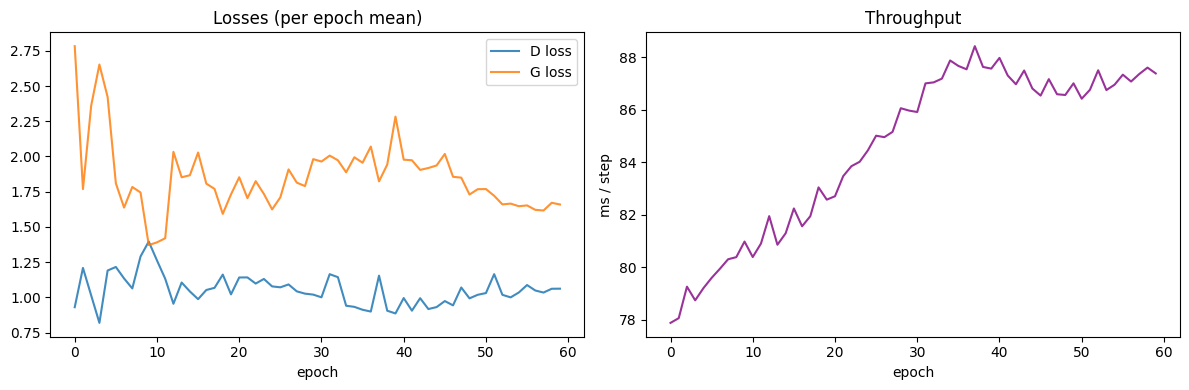

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].plot(history["d_loss"], label="D loss", alpha=.85)
ax[0].plot(history["g_loss"], label="G loss", alpha=.85)
ax[0].set_title("Losses (per epoch mean)"); ax[0].set_xlabel("epoch"); ax[0].legend()

ax[1].plot(history["ms_per_step"], color="purple", alpha=.8)
ax[1].set_title("Throughput"); ax[1].set_xlabel("epoch"); ax[1].set_ylabel("ms / step")
plt.tight_layout(); plt.show()


## 9. Final generated samples

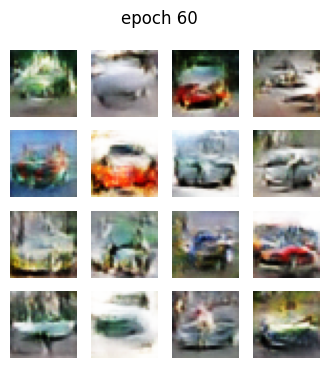

In [10]:
save_sample_grid(EPOCHS, noise=tf.random.normal([16, LATENT_DIM]), show=True);

## 10. Controlling the noise vector

A trained GAN maps the 100-d latent space to images through a *smooth* function. We probe that structure
three ways.

### 10a. Latent interpolation
Walk linearly from one random noise vector `z_a` to another `z_b`. If the generator learned a continuous
manifold (rather than memorizing samples) the outputs should morph **smoothly**.


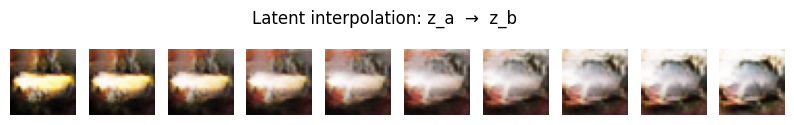

In [11]:
def interpolate(n=10, seed=None):
    rng = np.random.default_rng(seed)
    z_a = rng.normal(0, 1, (1, LATENT_DIM)).astype("float32")
    z_b = rng.normal(0, 1, (1, LATENT_DIM)).astype("float32")
    alphas = np.linspace(0, 1, n).reshape(-1, 1)
    zs = (1 - alphas) * z_a + alphas * z_b            # linear interpolation
    imgs = generator(zs, training=False).numpy()
    imgs = np.clip((imgs + 1) / 2, 0, 1)

    fig, axs = plt.subplots(1, n, figsize=(n, 1.5))
    for i in range(n):
        axs[i].imshow(imgs[i]); axs[i].axis("off")
    fig.suptitle("Latent interpolation: z_a  →  z_b")
    plt.show()

interpolate(n=10, seed=0)


### 10b. Per-dimension sweep
Hold a base noise vector fixed and vary **one coordinate at a time** from −3 to +3. Each row isolates the
effect of a single latent dimension — individual dimensions often control a recognizable visual factor
(color, orientation, lighting).


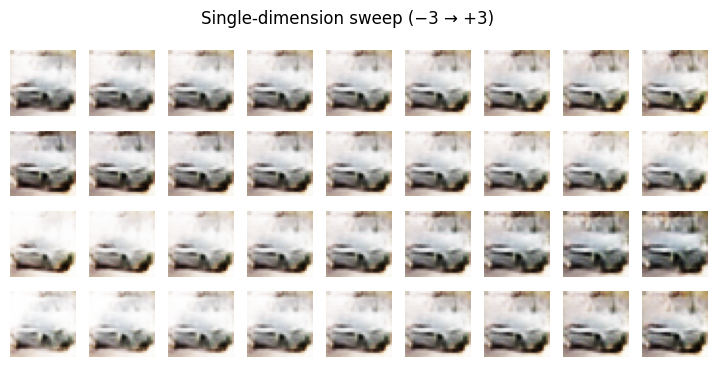

In [12]:
def dim_sweep(dims=(0, 10, 25, 50), n=9, seed=7):
    rng = np.random.default_rng(seed)
    base = rng.normal(0, 1, (1, LATENT_DIM)).astype("float32")
    values = np.linspace(-3, 3, n)

    fig, axs = plt.subplots(len(dims), n, figsize=(n, len(dims)))
    for r, d in enumerate(dims):
        zs = np.repeat(base, n, axis=0).copy()
        zs[:, d] = values                             # sweep one coordinate
        imgs = generator(zs, training=False).numpy()
        imgs = np.clip((imgs + 1) / 2, 0, 1)
        for c in range(n):
            axs[r, c].imshow(imgs[c]); axs[r, c].axis("off")
        axs[r, 0].set_ylabel(f"dim {d}", rotation=0, labelpad=25, va="center")
    fig.suptitle("Single-dimension sweep (−3 → +3)")
    plt.show()

dim_sweep(dims=(0, 10, 25, 50), n=9, seed=7)


### 10c. Noise-magnitude scaling (bonus)
Scale a fixed noise direction by increasing magnitudes. Near `0` the output is the "average"
automobile; larger magnitudes push toward the tails of the distribution and more extreme / varied samples.


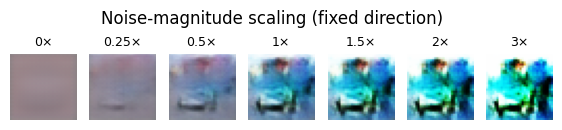

In [13]:
def magnitude_sweep(scales=(0.0, 0.25, 0.5, 1.0, 1.5, 2.0, 3.0), seed=3):
    rng = np.random.default_rng(seed)
    direction = rng.normal(0, 1, (1, LATENT_DIM)).astype("float32")
    zs = np.vstack([s * direction for s in scales])
    imgs = generator(zs, training=False).numpy()
    imgs = np.clip((imgs + 1) / 2, 0, 1)

    fig, axs = plt.subplots(1, len(scales), figsize=(len(scales), 1.6))
    for i, s in enumerate(scales):
        axs[i].imshow(imgs[i]); axs[i].axis("off"); axs[i].set_title(f"{s:g}×", fontsize=9)
    fig.suptitle("Noise-magnitude scaling (fixed direction)")
    plt.show()

magnitude_sweep()


## 11. Summary (AI-generated version)

Final metrics (fill in after a full Colab run from the printed output):

```
mean ms/step   : <see section 7/8>
total wall-clock: <min>
final D/G loss : <see section 8>
```


In [14]:
print("=" * 60)
print("AI-GENERATED DCGAN — SUMMARY")
print("=" * 60)
print(f"target class     : {TARGET_CLASS}  ({X.shape[0]} images)")
print(f"latent dim       : {LATENT_DIM}")
print(f"batch size       : {BATCH_SIZE}   steps/epoch: {STEPS_PER_EPOCH}")
print(f"epochs trained   : {len(history['d_loss'])}")
if history["ms_per_step"]:
    valid = [m for m in history["ms_per_step"] if m == m]  # drop NaN
    print(f"mean ms/step     : {np.mean(valid):.1f}")
if history["d_loss"]:
    print(f"final d_loss     : {history['d_loss'][-1]:.3f}")
    print(f"final g_loss     : {history['g_loss'][-1]:.3f}")
print(f"sample grids in  : {OUT_DIR}/")


AI-GENERATED DCGAN — SUMMARY
target class     : automobile  (6000 images)
latent dim       : 100
batch size       : 128   steps/epoch: 46
epochs trained   : 60
mean ms/step     : 84.5
final d_loss     : 1.062
final g_loss     : 1.660
sample grids in  : samples_ai/


### Efficiency / quality features implemented
- **`tf.data` input pipeline** (`cache → shuffle → batch(drop_remainder) → prefetch(AUTOTUNE)`) instead of
  per-step NumPy index sampling.
- **Single `@tf.function` training step** with a fixed `input_signature` → the graph is traced **once** and
  reused every step; no `generator.predict` + repeated `train_on_batch`, no per-step retracing.
- Two `GradientTape`s inside one compiled step update **D then G** with explicit `apply_gradients`.
- **`from_logits=True`** BCE (discriminator outputs raw logits) for numerical stability.
- **One-sided label smoothing** (real target = 0.9) to curb discriminator over-confidence.
- DCGAN conventions: **`RandomNormal(0, 0.02)` init**, `BatchNormalization`, `LeakyReLU(0.2)`,
  `Dropout(0.3)` in the discriminator, `tanh` generator output on **[-1, 1]** data.
- **Metrics for comparison**: per-epoch loss curves + **wall-clock ms/step** (first/tracing step excluded)
  + periodic **sample grids saved to disk** on a fixed noise seed.
- **Noise-vector control**: latent interpolation, per-dimension sweep, and a magnitude-scaling bonus.
- **Colab-ready**: `keras.datasets.cifar10.load_data()` + `os.makedirs(exist_ok=True)`; runs on GPU or CPU.
